<h1>Transformer Text Generator</h1>

<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

The goal of this project is to build a text generator using a Transformer model. The model will be trained on Sherlock Holmes text from Project Gutenberg.

The aim is to understand how a Transformer learns from text and how different model settings affect the quality of generated text.

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

The dataset consists of the book `The case-book of Sherlock Holmes by Arthur Conan Doyle`, which was downloaded from [Project Gutenberg](https://www.gutenberg.org/). The dataset contains English language stories about Sherlock Holmes and provides the material for training the text generation model.

In [1]:
#%pip install sentencepiece (run if needed)

In [24]:
import os

import numpy as np
import keras
import sentencepiece as spm
import matplotlib.pyplot as plt

# set a random seed for reproducibility (results are reproducible when the whole notebook 
# is run from top to bottom)
seed = 54
keras.utils.set_random_seed(seed)

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


In [3]:
file_path = "./txt/The_Project_Gutenberg.txt"
size_bytes = os.path.getsize(file_path)

with open(file_path, 'r', encoding='utf-8-sig') as file: # load the project gutenberg text
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f'File size: {round(size_bytes / 1024, 2)} KB')
print(f"First 100 characters: {text[:100]}")

Text length: 473158 characters
File size: 462.19 KB
First 100 characters: The Project Gutenberg eBook of The case-book of Sherlock Holmes
    
This eBook is for the use of an


As we can see, the dataset length consist of 473,158 characters. Note that this contains the license texts before and after the actual e-book. The file size is 462 KB. The first 100 characters show the beginning of the book.

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.

The code trains a SentencePiece tokenizer using the Gutenberg text dataset with the Byte Pair Encoding algorithm. The goal is to create a BPE based tokenizer trained on Gutenberg text that splits text into smaller, reusable token units. 

License text from the beginning and end is removed. The original full text is saved into `text` variable, and the clean text without license text into `clean_text`. The `clean_text` contains 453,762 characters.

In [18]:
# remove license text from the beginning and end
start = text.find("*** START OF")
start = text.find("\n", start) + 1
end = text.find("*** END OF")
clean_text = text[start:end]
print("Original text lenght:", len(text), "\nLength after license texts removed:", len(clean_text))

Original text lenght: 473158 
Length after license texts removed: 453762


Next we create two tokenizers: one trained with the raw text, including the Project Gutenberg license text, and the other without the license text. Later we train a model with each tokenizer and compare the results.

### Tokenizer with the license text
This tokenizer users the raw `text` including the license text. The trained SentencePiece tokenizer is saved into `sp`, which uses prefix `gutenberg_sp`. 

In [4]:
# train SentencePiece model
# save text to a temporary file for SentencePiece training

temp_file = 'gutenberg_temp.txt' # saves text into temporarily file
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# train SentencePiece model
vocab_size = 2000  # smaller target number of tokens
model_prefix = 'gutenberg_sp' # defines the prefix for the saved model files

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0, # aims to cover all characters in the training data
    model_type='bpe', # Byte Pair Encoding
    user_defined_symbols=['<PAD>', '<UNK>'] # adds <PAD> and <UNK> as special tokens
)

# load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# test tokenization
test_text = "It was from the Carlton Club"
tokens = sp.encode_as_pieces(test_text)

print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'lt', 'on', '▁C', 'l', 'ub']
Vocabulary size: 2000


Finally, the trained tokenizer is loaded and tested by tokenizing the sentence "It was from the Carlton Club". The code prints the resulting tokens and the actual vocabulary size.

Next we prepare the tokenized Gutenberg text for training a language model.

In [5]:
# prepare training data
# converts the text into numerical token ids using the trained SentencePiece tokenizer.

seq_length = 64 # each input sequence contains 64 tokens
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# creates overlapping sequences of 65 tokens, where the model uses the first 64 tokens to predict the next 64 tokens
sequences = []
for i in range(0, len(pieces) - seq_length):
    # Input: first seq_length tokens, Target: next seq_length tokens (shifted by 1)
    sequences.append(pieces[i:i+seq_length+1])

# shifts each sequence by one position and convert to NumPy array
sequences = np.array(sequences) # 
inputs = sequences[:, :-1]  # All tokens except the last one
targets = sequences[:, 1:]  # All tokens except the first one

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# Split into training and validation sets: Uses the first 90% of the text for training and the remaining 10% for validation.
# Skips 64 sequences at the split boundary to prevent overlapping tokens between training and validation sets.
# Skipping seq_length windows at the split point leaves no shared tokens between the sets.
split = int(0.9 * len(sequences))
train_inputs, train_targets = inputs[:split], targets[:split]
val_inputs, val_targets = inputs[split + seq_length:], targets[split + seq_length:]

Total tokens: 138589
Number of sequences: 138525
Input shape: (138525, 64)
Target shape: (138525, 64)


### Clean tokenizer without the license text
The tokenizer uses the `clean_text`, which does not have the license text. The trained SentencePiece tokenizer is saved into `sp_clean`, which uses prefix `gutenberg_sp_clean`. 

In [19]:
# train SentencePiece model on the cleaned text (license text removed)
# save clean text to a temporary file for SentencePiece training

temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

# train SentencePiece model
vocab_size = 2000
model_prefix_clean = 'gutenberg_sp_clean'  # separate prefix so the first tokenizer is not overwritten

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_clean,
    vocab_size=vocab_size,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# load the trained tokenizer
sp_clean = spm.SentencePieceProcessor()
sp_clean.load(f"{model_prefix_clean}.model")

# test tokenization
test_text = "It was from the Carlton Club"
tokens = sp_clean.encode_as_pieces(test_text)

print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_clean.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'lt', 'on', '▁C', 'l', 'ub']
Vocabulary size: 2000


Let's we prepare the tokenized clean text for training a language model.

In [20]:
# prepare training data from the cleaned text

seq_length = 64
pieces_clean = sp_clean.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_clean)}")

sequences_clean = []
for i in range(0, len(pieces_clean) - seq_length):
    sequences_clean.append(pieces_clean[i:i+seq_length+1])

sequences_clean = np.array(sequences_clean)
inputs_clean = sequences_clean[:, :-1]
targets_clean = sequences_clean[:, 1:]

print(f"Number of sequences: {len(sequences_clean)}")
print(f"Input shape: {inputs_clean.shape}")
print(f"Target shape: {targets_clean.shape}")

# 90 % train / 10 % validation, skipping seq_length sequences at the boundary
split_clean = int(0.9 * len(sequences_clean))
train_inputs_clean = inputs_clean[:split_clean]
train_targets_clean = targets_clean[:split_clean]
val_inputs_clean = inputs_clean[split_clean + seq_length:]
val_targets_clean = targets_clean[split_clean + seq_length:]

Total tokens: 132112
Number of sequences: 132048
Input shape: (132048, 64)
Target shape: (132048, 64)


The tokenizer with clean text has less tokens than the first tokenizer with raw text.

<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.

### Model 1

Here we build a small Transformer-based language model that learns to predict the next token in a sequence. This model uses the first tokenizer trained with raw text (the license text included).

In [6]:
# define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2


# create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# create model
model = keras.Model(inputs=inputs, outputs=outputs)

# compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 64)    │    128,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# train the model
batch_size = 32
epochs = 30

history_01 = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/30
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 302s 76ms/step - accuracy: 0.1557 - loss: 4.7403 - val_accuracy: 0.1397 - val_loss: 5.2693 - learning_rate: 3.0000e-04
Epoch 2/30
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 280s 72ms/step - accuracy: 0.2286 - loss: 3.7478 - val_accuracy: 0.1565 - val_loss: 5.4476 - learning_rate: 3.0000e-04
Epoch 3/30
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 277s 71ms/step - accuracy: 0.2625 - loss: 3.4524 - val_accuracy: 0.1608 - val_loss: 5.6203 - learning_rate: 1.5000e-04
Epoch 4/30
3896/3896 ━━━━━━━━━━━━━━━━━━━━ 277s 71ms/step - accuracy: 0.2771 - loss: 3.3365 - val_accuracy: 0.1620 - val_loss: 5.7246 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


`EarlyStopping` measures `val_loss` as default and saves the best model based on the best `val_loss` value.

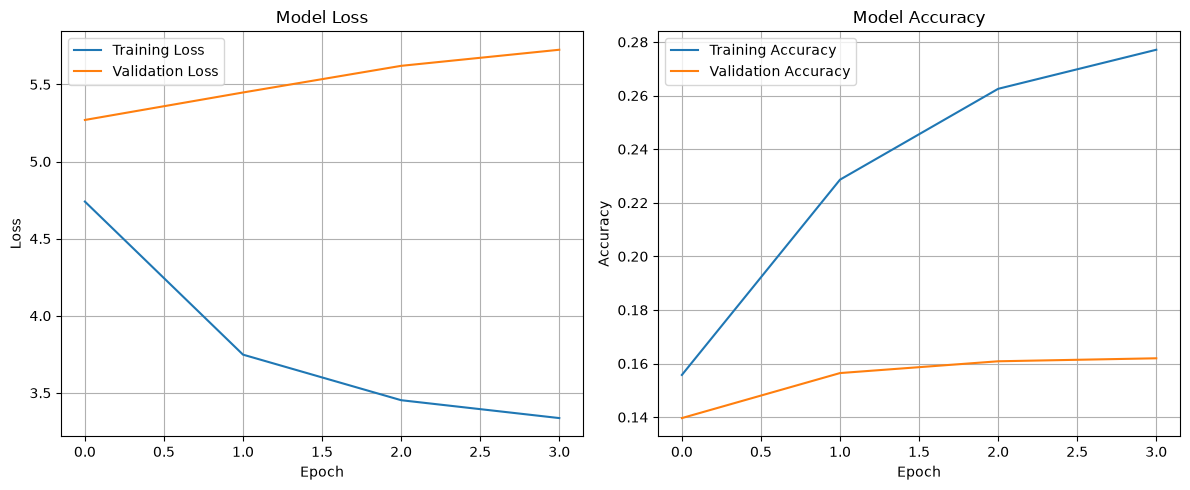

In [22]:
# function to plot training metrics
def plot_training_metrics(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid()
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_metrics(history_01)

In [9]:
# save the model
model.save('gutenberg_model.keras')
print("Model saved as 'gutenberg_model.keras'")

Model saved as 'gutenberg_model.keras'


In [10]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [11]:
# generate sample text
prompts = [
    "It was from the Carlton Club",
    "Have you ever heard of Baron Gruner?",
    "Then you will sympathize with the client",
    "Our visitor was greatly disturbed"
]


for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: It was from the Carlton Club
It was from the Carlton Clubthough he did snutes several fear I am did not anything about scream had add-played inodger cleent. But the rivioy who S thought that Mr. Holmes?" "DERlish Suso he believe I stood emrunked a poor view which We collecting a big people to the ner Gables, for him place you might do deposed me upon you with the other tent girl pocket-landildiecent had there was

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? If miss so I take this old horrars it is where said I spoke upon my grave orden Spowron. I four narr meetting why we talken those other morning." "You insolestiged to touch her past usalation forgag any value guection this happening." Oarrictive. Aour vlow!" said he asked Murdoch seamlt show we bringing out the dead years as joy of some vent

Prompt: Then you will sympathize with the client
Then you will sympathize with the client dismission but to be friend in Miss Wub boy. Then other 

In [12]:
# load model (if you're starting a new session)
# uncomment these lines to load a previously saved model
"""
# Load saved model
model = keras.models.load_model('gutenberg_model.keras')

# Load SentencePiece tokenizer
sp = spm.SentencePieceProcessor()
sp.load('gutenberg_sp.model')

# Test generation
prompt = "Our visitor was greatly disturbed"
generated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)
print(generated)
"""

'\n# Load saved model\nmodel = keras.models.load_model(\'gutenberg_model.keras\')\n\n# Load SentencePiece tokenizer\nsp = spm.SentencePieceProcessor()\nsp.load(\'gutenberg_sp.model\')\n\n# Test generation\nprompt = "Our visitor was greatly disturbed"\ngenerated = generate_text(model, sp, prompt, num_tokens=150, temperature=1.0)\nprint(generated)\n'

### Model 2

The next model is similar as model 1, but this time with the second tokenizer with clean text (the license text removed). The model is stored as `model_clean`.

In [23]:
# define model parameters (same as model 1)
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 64, 64)    │    128,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 64, 64)    │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add_5[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 64, 64)    │          0 │ add_5[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_9[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Next we train the model. The history is saved as `history_02`. Like in the model 1, `EarlyStopping` is used.

In [25]:
batch_size = 32
epochs = 30

history_02 = model_clean.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean.keras', save_best_only=True)
    ]
)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 298s 79ms/step - accuracy: 0.1497 - loss: 4.8210 - val_accuracy: 0.1629 - val_loss: 4.6310 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 274s 74ms/step - accuracy: 0.2235 - loss: 3.8000 - val_accuracy: 0.1792 - val_loss: 4.6600 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 273s 74ms/step - accuracy: 0.2577 - loss: 3.4870 - val_accuracy: 0.1833 - val_loss: 4.7382 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 274s 74ms/step - accuracy: 0.2734 - loss: 3.3623 - val_accuracy: 0.1829 - val_loss: 4.7888 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


Next we plot the training metrics and save the model as `gutenberg_model_clean.keras`.

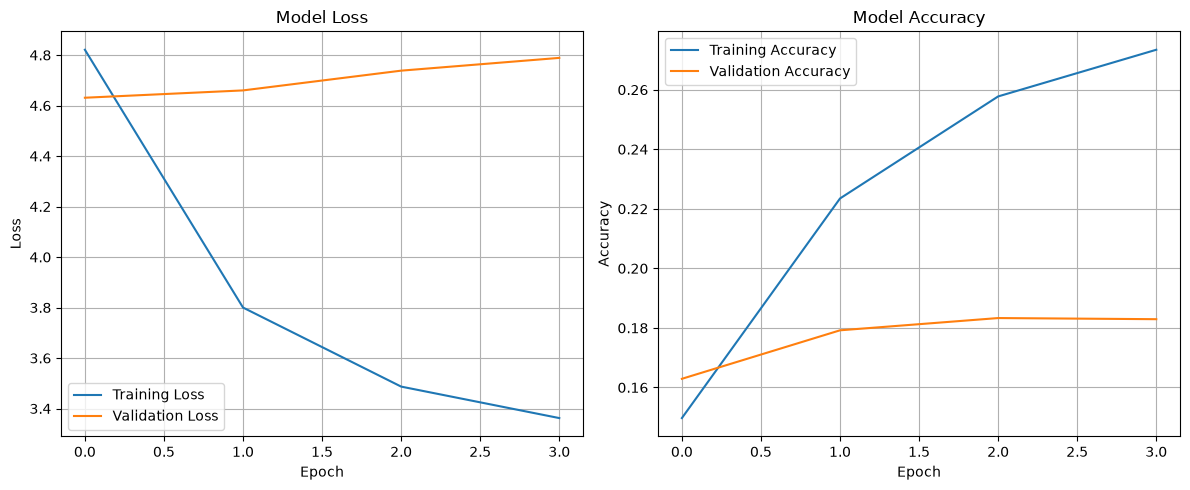

In [26]:
# plot
plot_training_metrics(history_02)

# save the model
model_clean.save('gutenberg_model_clean.keras')

Let's generate text with the same sample text (`prompt`) generated in Model 1 section. We use the same number of tokens (100) and temperature (1.2) as with model 1, so we can compare the results.

In [27]:
for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model_clean, sp_clean, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: It was from the Carlton Club
It was from the Carlton Clubxt upon the world miars while our caction of heart like importantle col'ticat and never heard." "Becut! The bit further Sere us or my plet and circag miss, and speak of resings, or the detek full stone. Wasinoolcon to fear. This denot away in some scoured being musence with the suck a viction'tos each side of his adver

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? What, there you might track.' Gibson, that he again before I speak so how sooner am. I could, we imposs to sight possibleiows, rusion of those sp when I was a wild to do when sal. His fatherative had out asy intellted that when she lipped those hadfully emergedech in the detemernourance. "Thickween sucatenses Gibson. Down very exual that he

Prompt: Then you will sympathize with the client
Then you will sympathize with the client spished fiances." "Yes, you interest at least possible terri reermace, if it is seen me. Murdoch

Let's print the training results from the best epoch.

In [31]:
# get the best epoch
best_epoch = int(np.argmin(history_02.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_02.history[key][best_epoch]:.4f}")

Best epoch: 1
loss: 4.8210
accuracy: 0.1497
val_loss: 4.6310
val_accuracy: 0.1629


The training results are better than in model 1 since we removed the license text. The model is overfitted.

### Model 3
Let's try to reduce overfitting with a higher dropout value. The previous was 0.1, and now we try 0.3. Otherwise this model is same as the model 2. Let's save this model as `model_clean_dropout03`.

In [32]:
# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.3
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.3)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_dropout03 = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_dropout03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_dropout03.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 64, 64)    │    128,000 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 64, 64)    │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add_10[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_10[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, 64, 64)    │          0 │ add_10[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_13[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64, 2000)  │    130,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 281s 74ms/step - accuracy: 0.1386 - loss: 4.9523 - val_accuracy: 0.1583 - val_loss: 4.6708 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 274s 74ms/step - accuracy: 0.2060 - loss: 3.9130 - val_accuracy: 0.1739 - val_loss: 4.6524 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 273s 74ms/step - accuracy: 0.2382 - loss: 3.5716 - val_accuracy: 0.1811 - val_loss: 4.7796 - learning_rate: 3.0000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 322s 73ms/step - accuracy: 0.2600 - loss: 3.3865 - val_accuracy: 0.1829 - val_loss: 4.8626 - learning_rate: 1.5000e-04
Epoch 5/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 274s 74ms/step - accuracy: 0.2700 - loss: 3.3088 - val_accuracy: 0.1842 - val_loss: 4.9062 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


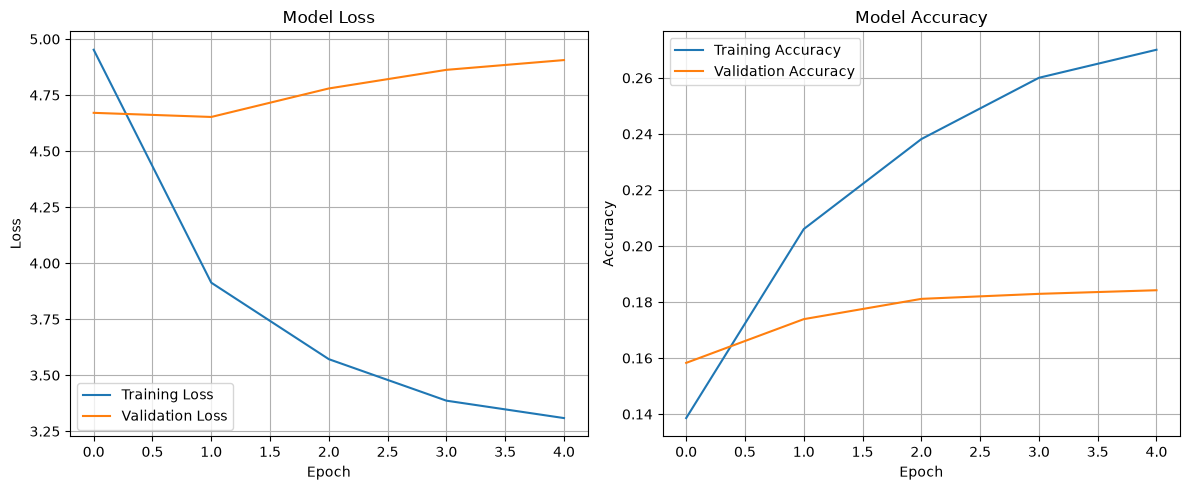

Best epoch: 2
loss: 3.9130
accuracy: 0.2060
val_loss: 4.6524
val_accuracy: 0.1739


In [33]:
# train
batch_size = 32
epochs = 30

history_03 = model_clean_dropout03.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_dropout03.keras', save_best_only=True)
    ]
)

# plot training results
plot_training_metrics(history_03)

# save the model
model_clean_dropout03.save('gutenberg_model_clean_dropout03.keras')

# get the best epoch
best_epoch = int(np.argmin(history_03.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_03.history[key][best_epoch]:.4f}")

### Model 4
Next, we try a smaller model. Let's change dropout back to 0.1. The model is saved as `model_clean_small`.

In [34]:
# define model parameters
embed_dim = 32
num_heads = 2
ff_dim = 64
num_layers = 1

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_small = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_small.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_small.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 64, 32)    │     64,000 │ input_layer_9[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 64, 32)    │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 32)    │      4,224 │ add_15[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_15[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 64, 32)    │          0 │ add_15[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_16[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 64, 32)    │      4,192 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_17 (Add)        │ (None, 64, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 32)    │         64 │ add_17[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 64, 2000)  │     66,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 138,544 (541.19 KB)

 Trainable params: 138,544 (541.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 201s 53ms/step - accuracy: 0.1290 - loss: 5.1193 - val_accuracy: 0.1446 - val_loss: 4.8283 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 197s 53ms/step - accuracy: 0.1780 - loss: 4.2312 - val_accuracy: 0.1515 - val_loss: 4.7723 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 194s 52ms/step - accuracy: 0.1884 - loss: 4.0527 - val_accuracy: 0.1597 - val_loss: 4.7795 - learning_rate: 3.0000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 197s 53ms/step - accuracy: 0.1963 - loss: 3.9615 - val_accuracy: 0.1623 - val_loss: 4.7846 - learning_rate: 1.5000e-04
Epoch 5/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 197s 53ms/step - accuracy: 0.1998 - loss: 3.9243 - val_accuracy: 0.1636 - val_loss: 4.7875 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


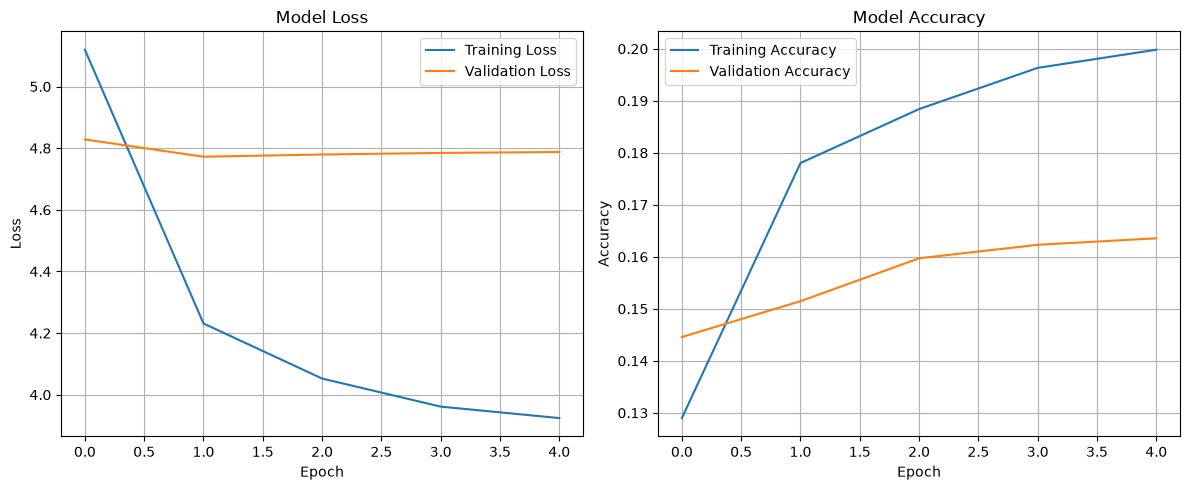

Best epoch: 2
loss: 4.2312
accuracy: 0.1780
val_loss: 4.7723
val_accuracy: 0.1515


In [35]:
# train
batch_size = 32
epochs = 30

history_04 = model_clean_small.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_small.keras', save_best_only=True)
    ]
)

# plot training results
plot_training_metrics(history_04)

# save the model
model_clean_small.save('gutenberg_model_clean_small.keras')

# get the best epoch
best_epoch = int(np.argmin(history_04.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_04.history[key][best_epoch]:.4f}")

### Model 5
Next, we try a model with a smaller vocabulary (1000). New tokenizer is created.

In [40]:
# tokenizer with vocab size 1000, trained on the clean text
temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

vocab_size_v1000 = 1000
model_prefix_v1000 = 'gutenberg_sp_v1000'

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_v1000,
    vocab_size=vocab_size_v1000,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

sp_v1000 = spm.SentencePieceProcessor()
sp_v1000.load(f"{model_prefix_v1000}.model")

tokens = sp_v1000.encode_as_pieces("It was from the Carlton Club")
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_v1000.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'l', 't', 'on', '▁C', 'l', 'ub']
Vocabulary size: 1000


Then we prepare the training data.

In [41]:
# prepare training data with the 1000-token vocabulary
pieces_v1000 = sp_v1000.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_v1000)}")

sequences_v1000 = []
for i in range(0, len(pieces_v1000) - seq_length):
    sequences_v1000.append(pieces_v1000[i:i + seq_length + 1])

sequences_v1000 = np.array(sequences_v1000)
inputs_v1000 = sequences_v1000[:, :-1]
targets_v1000 = sequences_v1000[:, 1:]

print(f"Number of sequences: {len(sequences_v1000)}")
print(f"Input shape: {inputs_v1000.shape}")

# 90 % train / 10 % validation
split_v1000 = int(0.9 * len(sequences_v1000))
train_inputs_v1000 = inputs_v1000[:split_v1000]
train_targets_v1000 = targets_v1000[:split_v1000]
val_inputs_v1000 = inputs_v1000[split_v1000 + seq_length:]
val_targets_v1000 = targets_v1000[split_v1000 + seq_length:]

Total tokens: 153183
Number of sequences: 153119
Input shape: (153119, 64)


Next, we create the model.

In [43]:
# define model parameters (same as model 2)
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_v1000_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_v1000.get_piece_size(), embed_dim)(inputs_v1000_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_v1000 = keras.layers.Dense(sp_v1000.get_piece_size())(x)

model_clean_v1000 = keras.Model(inputs=inputs_v1000_layer, outputs=outputs_v1000)

model_clean_v1000.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_v1000.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 64, 64)    │     64,000 │ input_layer_11[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_18 (Add)        │ (None, 64, 64)    │          0 │ embedding_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ add_18[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_18[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_19 (Add)        │ (None, 64, 64)    │          0 │ add_18[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_19[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_20 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_20[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_21 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_21[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 64, 64)    │     16,576 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_22 (Add)        │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_22[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 64, 1000)  │     65,000 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 195,944 (765.41 KB)

 Trainable params: 195,944 (765.41 KB)

 Non-trainable params: 0 (0.00 B)

Let's train it.

In [44]:
batch_size = 32
epochs = 30

history_05 = model_clean_v1000.fit(
    train_inputs_v1000, train_targets_v1000,
    validation_data=(val_inputs_v1000, val_targets_v1000),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_v1000.keras', save_best_only=True)
    ]
)

Epoch 1/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 229s 52ms/step - accuracy: 0.1518 - loss: 4.4237 - val_accuracy: 0.1766 - val_loss: 4.1593 - learning_rate: 3.0000e-04
Epoch 2/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 219s 51ms/step - accuracy: 0.2252 - loss: 3.6413 - val_accuracy: 0.2104 - val_loss: 4.0582 - learning_rate: 3.0000e-04
Epoch 3/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 219s 51ms/step - accuracy: 0.2608 - loss: 3.3963 - val_accuracy: 0.2217 - val_loss: 4.0821 - learning_rate: 3.0000e-04
Epoch 4/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 220s 51ms/step - accuracy: 0.2801 - loss: 3.2665 - val_accuracy: 0.2255 - val_loss: 4.1013 - learning_rate: 1.5000e-04
Epoch 5/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 221s 51ms/step - accuracy: 0.2882 - loss: 3.2128 - val_accuracy: 0.2260 - val_loss: 4.1147 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


The training metrics:

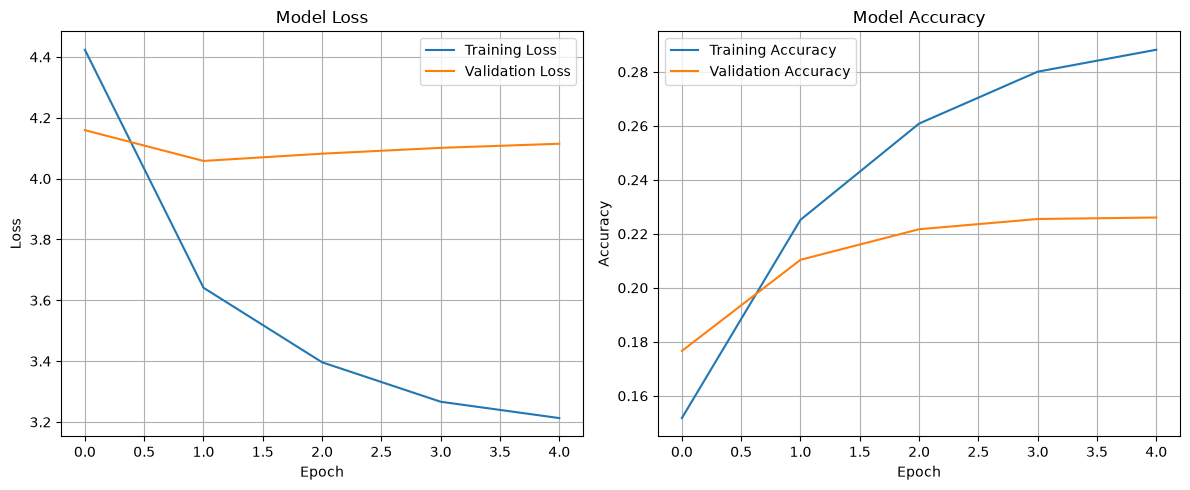

Best epoch: 2
loss: 3.6413
accuracy: 0.2252
val_loss: 4.0582
val_accuracy: 0.2104


In [45]:
plot_training_metrics(history_05)

model_clean_v1000.save('gutenberg_model_clean_v1000.keras')

best_epoch = int(np.argmin(history_05.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_05.history[key][best_epoch]:.4f}")

The model achieved a validation loss of 4.0582, which is the lowest of all the five models. However, this model has a smaller vocabulary of 1,000 tokens compared to the other models (2,000 tokens). Thus, model 5 is not straight compatible with other models.  

Validation loss measures the prediction error per one token. Different vocabulary sizes might result in different tokenizations of the same text, and the average length per token might be different. So, a lower validation loss might not necessarily mean that model 5 is better than the other models.

### Model comparison
Let's generate text with the models above and compare the results. We experiment with different temperatures: first 0.8 and then 1.0.

In [46]:
models_to_compare = {
    "Model 1 (raw, 2000)": (model, sp),
    "Model 2 (clean)": (model_clean, sp_clean),
    "Model 3 (clean, dropout 0.3)": (model_clean_dropout03, sp_clean),
    "Model 4 (small)": (model_clean_small, sp_clean),
    "Model 5 (vocabulary 1000)": (model_clean_v1000, sp_v1000),
}

for name, (m, tokenizer) in models_to_compare.items():
    print(f"\n{name}")
    for prompt in prompts[:2]:
        np.random.seed(54)   # same seed for every model
        print(f"\nPrompt: {prompt}")
        print(generate_text(m, tokenizer, prompt, num_tokens=60, temperature=0.8))


Model 1 (raw, 2000)

Prompt: It was from the Carlton Club
It was from the Carlton Clubbyeveire the date, Mr. I can only to never come away it." "Very it was a long room. "Sir innce then, Mr. Holmes?" "The man was a particular clearly correspondling cries--cause the _Here

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? It was a good wicked usual window to be as I saw him. A living-shotion of my life or we shall have a pulled upon this case." "Yes, you have you." He looked only feel his grewer. He played the same air of

Model 2 (clean)

Prompt: It was from the Carlton Club
It was from the Carlton Clubmace as he cae. But the matter is authorfices. Have you have a rate asion of those very hy of all-hounded and that I was a thirty. There had broken be able to make him. But the same extra

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? Dor man by a step forward off or a more than I found forced in the real. "Yes, I think

Next, we try with **temperature 1.0**.

In [47]:
# temperature 1.0
for name, (m, tokenizer) in models_to_compare.items():
    print(f"\n{name}")
    for prompt in prompts[:2]:
        np.random.seed(54)   # same seed for every model
        print(f"\nPrompt: {prompt}")
        print(generate_text(m, tokenizer, prompt, num_tokens=60, temperature=1.0))


Model 1 (raw, 2000)

Prompt: It was from the Carlton Club
It was from the Carlton Clubery there was very a huge professional easalap which was really inclonged by, and I have his note--ries of both which I'll took out it is no more friend and to bell. There were several evidence of answer to find him. Eid from Mr.

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? Watson would be any a perfectronmless the precious of something twgerousson. ought a man." "We were is another back to-land Yard, Mr. Holmes?" "The man that I ran down sheressed, in cloook and well-misement. He

Model 2 (clean)

Prompt: It was from the Carlton Club
It was from the Carlton Club sum Garrideb grim the beach. His moment the back of the murdit, and he left, and I elded with it." "My not? Wapssest." "The friend with the Lion-hign tragedy of ideaspish. We not actual from

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? But it was one maatic wish." "A

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.